# Cloaking meets inverse scattering: designed dielectric cloaks in the testbed

The testbed's forward model (isotropic, nonmagnetic, lossless dielectric, TM $E_z$, 40 transmitters, 60 receivers) is differentiable in the permittivity, so a cloak can be found by gradient descent on a shell of pixels. How deep can such a design go, what do first-order scattering and a sum rule say about this class of media, and what do the testbed's noise and sensitivity analysis make of the result? Andkjaer and Sigmund (2011) topology-optimized low-contrast all-dielectric cloaks that are nearly perfect for a few incidence angles in a limited band, as reproduced here for one view.

What this notebook shows:

- one transmitter can be made to see almost nothing, but the design is tuned to its discretized operator: on a finer grid it keeps only the depth of the model mismatch, while the same pixels re-tuned there are deep again;
- hiding the object from all 40 transmitters is far harder: the designs found reduce the scattered energy by a few dB, and free pixels against rings is not ranked;
- first-order (Born) scattering forbids canceling the forward amplitude with added dielectric, yet the full model reaches a deep single-view null; the rigorous statement is a sum rule on the integrated extinction;
- the notch is narrowband, and some designs scatter more than the bare core toward the ends of the swept range;
- in noise units the single-view design is hidden only when data and design share one operator, and every design is visible from all 40 views;
- the Fisher spectrum survives a cloak and a small change of the hidden core is as detectable through it: local sensitivity is not lost, but nothing is said about imaging the cloak itself.

This goes beyond the book, which supplies only the caveat that a cloak is a single-frequency device (CLAIMS.md entries H1 and H4; book section 33, eq. (33.5) and the discussion around it).

## Conventions

Time dependence $e^{-i\omega t}$: outgoing waves are Hankel functions of the first kind and loss is a positive imaginary part of $\epsilon$. Lengths are in free-space wavelengths, $\lambda_0 = 1$, $k_0 = 2\pi$, unless a section sweeps the wavelength. The polarization with $E$ along $z$ is called TM ($E_z$) here, as in DESIGN.md; the book calls it TE. The contrast is $\chi = \epsilon_r - 1$, arrays are indexed $[i,j] = [x,y]$, and the data are $d[t,r]$, the scattered field at receiver $r$ for a unit line source at transmitter $t$ (DESIGN sections 1 and 2). The domain is $4\times 4$ wavelengths on $64\times 64$ pixels (`ch15_setup(n=64, side=4.0)`).

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

# Figure style shared by every notebook in notebooks/cloaking (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, time
_src = pathlib.Path.cwd().resolve().parents[1] / "src"   # use the bayes_scatter that ships with this checkout
if (_src / "bayes_scatter").is_dir() and str(_src) not in sys.path:
    sys.path.insert(0, str(_src))
from scipy.optimize import minimize
from bayes_scatter.geometry import ch15_setup, Setup
from bayes_scatter.forward import Forward
from bayes_scatter.jacobian import jacobian_theta
from bayes_scatter.likelihood import noise_std_from_snr, add_noise
from bayes_scatter import phantoms
dB = lambda x: 10.0 * np.log10(x)

## 1. The forward model as a design tool

Per transmitter the discrete Lippmann-Schwinger system is $(I - G\,\mathrm{diag}\,\chi)\,u_t = u_{\mathrm{inc},t}$ and $d[t,r] = \sum_m R[r,m]\,\chi_m u_t[m]$ (DESIGN 2.2 and 2.3). The solve is differentiable by the adjoint method, so $\nabla_\chi\sum|d|^2$ costs about one extra solve per transmitter. The object to hide is a cylinder of radius 0.4 with $\epsilon_r = 3$. The design region is the shell of pixels with centers in $0.4 + h/2 < r < 1.4$, with $\epsilon_r \in [1, 4]$ on each pixel. For a transmitter set $T$ the objective is the scattered energy relative to the bare core,
$$J_T(\chi) = \frac{\sum_{t\in T}\|d_t(\chi_{\mathrm{core}} + \chi_{\mathrm{shell}})\|^2}{\sum_{t\in T}\|d_t(\chi_{\mathrm{core}})\|^2},$$
reported in dB. Before trusting an optimizer, the gradient is checked against a finite difference (solver tolerance $10^{-10}$ for the check). That check shows that autodiff and finite differences of the same iterative solver agree; it does not bound the error of either against the exact derivative of the discretized problem, which would need a dense reference solve.

grid 64 x 64, h = 0.0625 wavelengths, design pixels: 1420
data shape (40, 60), bare core: mean |d|^2 = 1.8026e-04


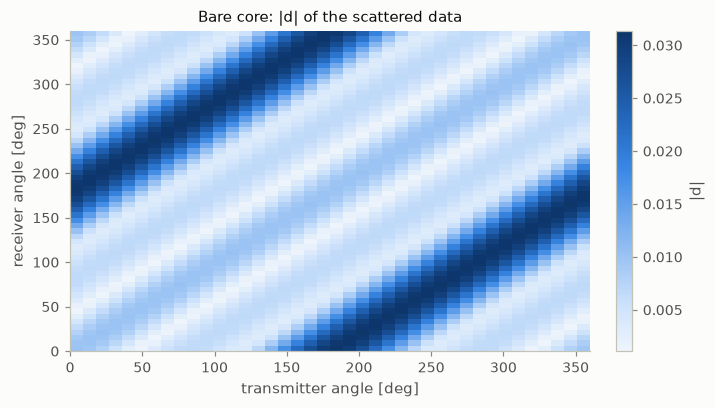

In [3]:
setup = ch15_setup(n=64, side=4.0)
grid = setup.grid
fwd = Forward(setup, tol=1e-6, restart=60)
X, Y = grid.centers()
RR = np.hypot(X, Y)
chi_core = np.asarray(phantoms.cylinder(grid, 0.4, 3.0))
shell = (RR > 0.4 + grid.h / 2) & (RR < 1.4)          # design region: pixel centers in the shell
idx = np.argwhere(shell)
d0, u0 = fwd(jnp.asarray(chi_core))
d0 = np.asarray(d0)
ang_tx = 360.0 * np.arange(40) / 40
ang_rx = 360.0 * np.arange(60) / 60
print(f"grid {grid.n} x {grid.n}, h = {grid.h:.4f} wavelengths, design pixels: {len(idx)}")
print(f"data shape {d0.shape}, bare core: mean |d|^2 = {np.mean(np.abs(d0)**2):.4e}")
fig, ax = plt.subplots(figsize=(6.4, 3.6))
im = ax.imshow(np.abs(d0).T, extent=[0, 360, 0, 360], aspect="auto", cmap="seq_blue")
ax.grid(False); ax.set_xlabel("transmitter angle [deg]"); ax.set_ylabel("receiver angle [deg]")
ax.set_title("Bare core: |d| of the scattered data")
fig.colorbar(im, ax=ax, label="|d|")
plt.show()

In [4]:
# Gradient check: directional finite difference against the jax gradient, with a tight-tolerance solver.
fwd10 = Forward(setup, tol=1e-10, restart=60)
E0_all = float(np.sum(np.abs(d0) ** 2))
def J_of_chi(chi, f):
    return jnp.sum(jnp.abs(f(chi)[0]) ** 2) / E0_all
render_free = lambda c: jnp.asarray(chi_core).at[idx[:, 0], idx[:, 1]].add(c)   # additive like render_ring; the core has no weight on shell pixels
c_start = jnp.full(len(idx), 0.5)
rng = np.random.default_rng(0)
v = rng.standard_normal(len(idx)); v /= np.linalg.norm(v)
g_ad = jax.grad(lambda c: J_of_chi(render_free(c), fwd10))(c_start)
step = 1e-3
fd = (J_of_chi(render_free(c_start + step * v), fwd10) - J_of_chi(render_free(c_start - step * v), fwd10)) / (2 * step)
ad = float(jnp.dot(g_ad, v))
print(f"directional derivative: autodiff {ad:.8e}, central difference {float(fd):.8e}")
# tolerance 1e-5: central-difference truncation (step^2 times a third derivative) plus solver error / step. This tests that AD and FD of the
# same iterative solver agree; it is not the accuracy of the derivative against a dense reference.
check("gradient, AD versus central difference, relative error", abs(ad - float(fd)) / abs(ad), 1e-5)

directional derivative: autodiff 1.36830776e-03, central difference 1.36830776e-03
PASS  gradient, AD versus central difference, relative error: got 2.04939e-09, target 0, |diff| 2.05e-09 <= 1e-05


## 2. Three designs

All three start from $\chi = 0.5$ on the shell and use L-BFGS-B with the bounds $0\le\chi\le 3$ (Byrd, Lu, Nocedal and Zhu 1995). (A) one transmitter, $T=\{0\}$, free pixels, at most 200 iterations. (B) all 40 transmitters, free pixels, at most 150 iterations. (C) all 40 transmitters, a radially symmetric shell of 11 rings (ring width about $1.5h$), at most 100 iterations; C2 is the ring family from a second start, a high-index inner shell (compare notebook 04, section 3, for single shells). The ring rendering has a half-pixel vacuum gap next to the core, because design pixels have centers beyond $0.4 + h/2$. The table gives both objectives, iteration counts and optimizer messages: stopping before the cap means the optimizer's own test was met, reaching it means budget-limited. The depth of A varies with the optimizer path and the thread environment; the all-transmitter columns move far less.

In [5]:
# Design machinery: L-BFGS-B on the pixels (or ring values) of the shell, objective J_T from the brief.
ring_edges = np.linspace(0.4, 1.4, int(round(1.0 / (1.5 * grid.h))) + 1)
rid = np.where(shell, np.clip(np.digitize(RR, ring_edges) - 1, 0, len(ring_edges) - 2), -1)
P = np.stack([(rid == k).astype(float) for k in range(len(ring_edges) - 1)], axis=-1)
render_ring = lambda c: jnp.asarray(chi_core) + jnp.einsum("ijk,k->ij", jnp.asarray(P), c)

def design(render, tsel, npar, maxit, x0=None):
    tj = jnp.asarray(tsel)
    E0 = float(np.sum(np.abs(d0[tsel]) ** 2))
    vg = jax.jit(jax.value_and_grad(lambda c: jnp.sum(jnp.abs(fwd(render(c))[0][tj]) ** 2) / E0))
    def fun(c):
        val, gr = vg(jnp.asarray(c))
        return float(val), np.asarray(gr, dtype=float)
    res = minimize(fun, np.full(npar, 0.5) if x0 is None else x0, jac=True, method="L-BFGS-B", bounds=[(0.0, 3.0)] * npar,
                   options=dict(maxiter=maxit, maxfun=maxit + 20))
    return np.asarray(render(jnp.asarray(res.x))), res

def Jdb(d, dref, tsel):
    return dB(np.sum(np.abs(d[tsel]) ** 2) / np.sum(np.abs(dref[tsel]) ** 2))

T0, ALL = np.array([0]), np.arange(40)
chiA, resA = design(render_free, T0, len(idx), 200)
chiB, resB = design(render_free, ALL, len(idx), 150)
chiC, resC = design(render_ring, ALL, P.shape[-1], 100)
ring_mid = 0.5 * (ring_edges[:-1] + ring_edges[1:])
chiC2, resC2 = design(render_ring, ALL, P.shape[-1], 100, x0=np.where(ring_mid < 0.7, 3.0, 0.0))   # second start for the ring family: inner shell at the bound
designs = {"A": chiA, "B": chiB, "C": chiC}
info = {"A": ("A: 1 tx, free pixels", resA), "B": ("B: 40 tx, free pixels", resB), "C": ("C: 40 tx, 11 rings", resC), "C2": ("C2: 11 rings, 2nd start", resC2)}
dd = {k: np.asarray(fwd(jnp.asarray(c))[0]) for k, c in designs.items()}
dd["C2"] = np.asarray(fwd(jnp.asarray(chiC2))[0])
print(f"{'design':24s} {'J(T={0}) [dB]':>14s} {'J(all) [dB]':>12s} {'iterations':>11s} {'evaluations':>12s}")
for k in ("A", "B", "C", "C2"):
    print(f"{info[k][0]:24s} {Jdb(dd[k], d0, T0):14.2f} {Jdb(dd[k], d0, ALL):12.2f} {info[k][1].nit:11d} {info[k][1].nfev:12d}")
for k in ("A", "B", "C", "C2"):
    print(f"optimizer message, {k}: {info[k][1].message}")
for k, c in (("A", chiA), ("B", chiB), ("C", chiC), ("C2", chiC2)):
    print(f"design {k}: eps_r range [{1 + c.min():.2f}, {1 + c.max():.2f}]"
          f" (shell: {1 + c[shell].min():.2f} to {1 + c[shell].max():.2f}),"
          f" fraction of shell pixels at a bound: {np.mean((c[shell] < 1e-3) | (c[shell] > 3 - 1e-3)):.2f}")
# thresholds are regression guards: A's depth moves by several dB with the thread environment, B's all-view value by well under 1 dB
check("design A beats the bare core for its own transmitter by 30 dB", float(Jdb(dd["A"], d0, T0) < -30), 0.0, 1.0)
check("design B beats the bare core summed over all transmitters", float(Jdb(dd["B"], d0, ALL) < -3), 0.0, 1.0)
check("both ring starts beat the bare core summed over all transmitters", float(max(Jdb(dd["C"], d0, ALL), Jdb(dd["C2"], d0, ALL)) < -3), 0.0, 1.0)

design                    J(T={0}) [dB]  J(all) [dB]  iterations  evaluations
A: 1 tx, free pixels             -46.54         2.36          48           51
B: 40 tx, free pixels             -7.87        -7.16         150          159
C: 40 tx, 11 rings                -5.43        -5.02          26           31
C2: 11 rings, 2nd start           -6.49        -6.14          19           20
optimizer message, A: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
optimizer message, B: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT
optimizer message, C: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
optimizer message, C2: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
design A: eps_r range [1.00, 3.46] (shell: 1.00 to 3.46), fraction of shell pixels at a bound: 0.37
design B: eps_r range [1.00, 4.00] (shell: 1.00 to 4.00), fraction of shell pixels at a bound: 0.90
design C: eps_r range [1.00, 4.00] (shell: 1.00 to 4.00), fraction of shell pixels at a bound: 0.68
design C2: eps_r range [1.

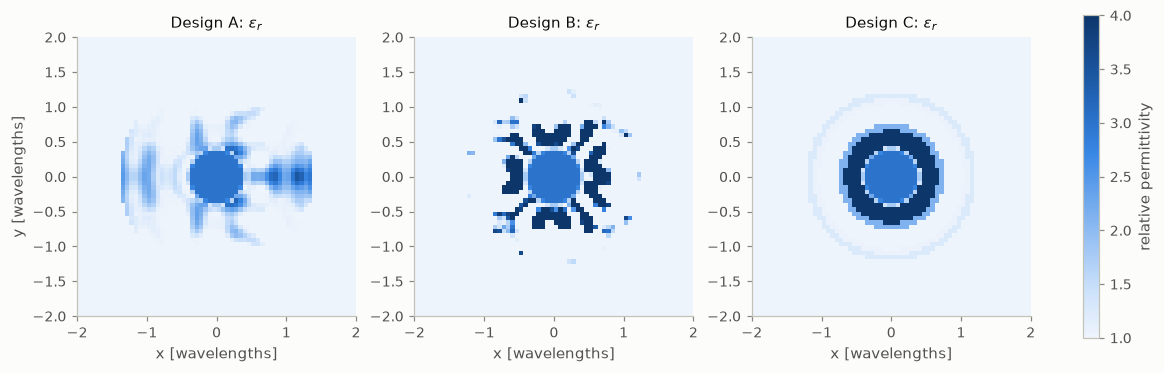

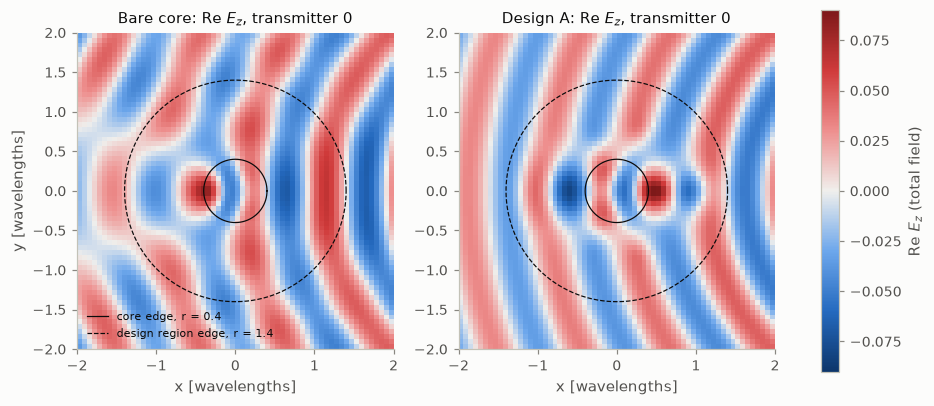

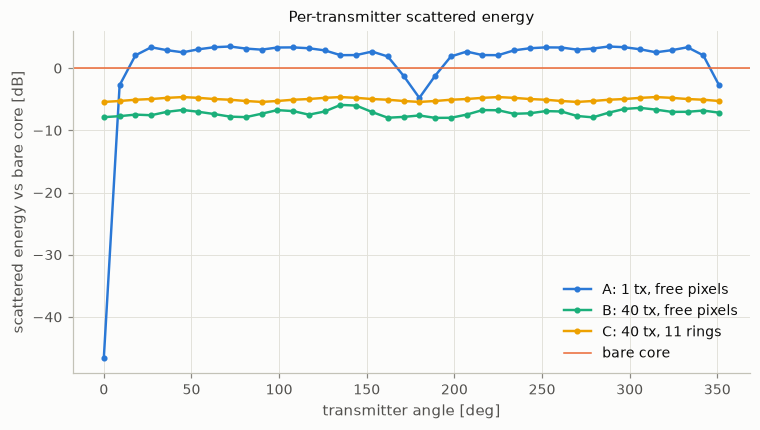

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.6))
for ax, k in zip(axs, "ABC"):
    im = ax.imshow(1 + designs[k].T, extent=[-2, 2, -2, 2], cmap="seq_blue", vmin=1, vmax=4)
    ax.grid(False); ax.set_title(f"Design {k}: $\\epsilon_r$"); ax.set_xlabel("x [wavelengths]")
axs[0].set_ylabel("y [wavelengths]")
fig.colorbar(im, ax=axs, label="relative permittivity", shrink=0.85)
plt.show()

th = np.linspace(0, 2 * np.pi, 400)
uA = np.asarray(fwd(jnp.asarray(chiA))[1][0])
lim = max(np.abs(u0[0].real).max(), np.abs(uA.real).max())
fig, axs = plt.subplots(1, 2, figsize=(8.4, 4.0))
for ax, u, t in zip(axs, (np.asarray(u0[0]), uA), ("Bare core", "Design A")):
    im = ax.imshow(u.real.T, extent=[-2, 2, -2, 2], cmap="div_blue_red", vmin=-lim, vmax=lim)
    for r in (0.4, 1.4):
        ax.plot(r * np.cos(th), r * np.sin(th), color=INK, lw=0.8, ls="--" if r > 0.5 else "-",
                label="core edge, r = 0.4" if r < 0.5 else "design region edge, r = 1.4")
    ax.grid(False); ax.set_title(f"{t}: Re $E_z$, transmitter 0"); ax.set_xlabel("x [wavelengths]")
axs[0].set_ylabel("y [wavelengths]"); axs[0].legend(loc="lower left", fontsize=7)
fig.colorbar(im, ax=axs, label="Re $E_z$ (total field)", shrink=0.85)
plt.show()

fig, ax = plt.subplots(figsize=(6.8, 3.8))
cols = {"A": CAT[0], "B": CAT[2], "C": CAT[3]}
for k in "ABC":
    ratio = np.sum(np.abs(dd[k]) ** 2, axis=1) / np.sum(np.abs(d0) ** 2, axis=1)
    ax.plot(ang_tx, dB(ratio), color=cols[k], marker="o", ms=3, label=info[k][0])
ax.axhline(0, color=CAT[1], lw=1.0, label="bare core")
ax.set_xlabel("transmitter angle [deg]"); ax.set_ylabel("scattered energy vs bare core [dB]")
ax.set_title("Per-transmitter scattered energy"); ax.legend()
plt.show()

The single-view design is smooth and concentrated along the incidence axis, the all-view design runs to the bounds, and the ring design is the restricted family. The last figure shows A deep for its own transmitter and, apart from a smaller reduction at its neighbors and the mirror transmitter, not elsewhere. For the all-view problem the free-pixel design and the two ring starts differ by little against their gap to the single-view notch; a few local runs do not rank the families.

**Discretization check.** The next cell replicates every pixel $2\times 2$, so the object is identical and only the integral equation changes ($h\to h/2$), solves again on $128\times128$, and compares; a $4\times4$ replication on $256\times256$ shows the trend. The bare core is also compared with the Mie series (`bayes_scatter.mie`, DESIGN section 8), which gives the model error of the pixelated cylinder. A fixed design evaluated with another operator leaves a residual equal to the difference of the operators acting on it, so the depth that can transfer is limited by that mismatch (printed in dB). Non-transfer does not show that a deep notch is an artifact, so the second cell continues design A on the $64\times64$ operator and re-tunes the same $1420$ pixels on the $128\times128$ operator, with L-BFGS-B on $\ln J_{\{0\}}$ so that the default stopping rules do not decide when to stop, and evaluates each result on all three grids.

In [7]:
# Discretization check: replicate every pixel 2 x 2 (n = 128) and 4 x 4 (n = 256); the object is identical, only the integral equation changes.
from bayes_scatter.mie import mie_scattered
rep_fwd = {f: Forward(ch15_setup(n=64 * f, side=4.0), tol=1e-6, restart=60) for f in (2, 4)}
rep_up = lambda c, f: np.kron(c, np.ones((f, f)))
d0r = {f: np.asarray(rep_fwd[f](jnp.asarray(rep_up(chi_core, f)))[0]) for f in (2, 4)}
ddr = {f: {k: np.asarray(rep_fwd[f](jnp.asarray(rep_up(c, f)))[0]) for k, c in designs.items()} for f in (2, 4)}
d_mie = mie_scattered(setup.antennas.tx, setup.antennas.rx, 0.4, 3.0)
rel = lambda a, b: np.linalg.norm(a - b) / np.linalg.norm(b)
print("bare core, relative data difference (Frobenius):")
print(f"  n=64 vs n=128 {rel(d0, d0r[2]):.3e}, n=128 vs n=256 {rel(d0r[2], d0r[4]):.3e}")
print(f"  against the analytic Mie series: n=64 {rel(d0, d_mie):.3e}, n=128 {rel(d0r[2], d_mie):.3e}, n=256 {rel(d0r[4], d_mie):.3e}"
      f"  (n=64: {20 * np.log10(rel(d0, d_mie)):.1f} dB in amplitude)")
print(f"{'design':24s} {'T={0}: n=64':>12s} {'128':>8s} {'256':>8s} {'all: n=64':>11s} {'128':>8s} {'256':>8s}   (dB)")
for k in "ABC":
    print(f"{info[k][0]:24s} {Jdb(dd[k], d0, T0):12.2f} {Jdb(ddr[2][k], d0r[2], T0):8.2f} {Jdb(ddr[4][k], d0r[4], T0):8.2f} "
          f"{Jdb(dd[k], d0, ALL):11.2f} {Jdb(ddr[2][k], d0r[2], ALL):8.2f} {Jdb(ddr[4][k], d0r[4], ALL):8.2f}")
for k in "ABC":
    print(f"design {k}: |d(128) - d(64)| / |d_bare| (T={{0}} rows) = {np.linalg.norm((ddr[2][k] - dd[k])[0]) / np.linalg.norm(d0[0]):.3e}"
          f", as an energy ratio {dB((np.linalg.norm((ddr[2][k] - dd[k])[0]) / np.linalg.norm(d0r[2][0])) ** 2):.2f} dB")
mismatch_dB = dB((np.linalg.norm((ddr[2]["A"] - dd["A"])[0]) / np.linalg.norm(d0r[2][0])) ** 2)

check("bare core: n = 64 data against the Mie series, relative error", rel(d0, d_mie), 0.06)   # observed ~3.5 percent: staircase discretization of the circle
check("bare core: n = 128 replication changes the data by less than 3 percent", rel(d0, d0r[2]), 0.03)   # observed ~1.7 percent
check("design A is still deeper than -20 dB on the n = 128 grid", float(Jdb(ddr[2]["A"], d0r[2], T0) < -20), 0.0, 1.0)   # guard only: A's fine-grid depth is path dependent
check("design A's depth on n = 128 equals the operator mismatch (dB) to within 3 dB", Jdb(ddr[2]["A"], d0r[2], T0), 3.0, mismatch_dB)   # d128(A) = d64(A) + mismatch, and |d64(A)| is far smaller
for k in "BC":   # tolerance: a few percent change of the data amplitude moves an energy ratio near -5 dB by well under 1 dB; observed 0.3 dB
    check(f"design {k}: all-transmitter J moves by less than 0.5 dB on the n = 128 grid", Jdb(ddr[2][k], d0r[2], ALL), 0.5, Jdb(dd[k], d0, ALL))

bare core, relative data difference (Frobenius):
  n=64 vs n=128 1.688e-02, n=128 vs n=256 4.395e-03
  against the analytic Mie series: n=64 3.492e-02, n=128 2.309e-02, n=256 2.115e-02  (n=64: -29.1 dB in amplitude)
design                    T={0}: n=64      128      256   all: n=64      128      256   (dB)
A: 1 tx, free pixels           -46.54   -28.49   -26.51        2.36     2.35     2.35
B: 40 tx, free pixels           -7.87    -7.69    -7.64       -7.16    -6.91    -6.84
C: 40 tx, 11 rings              -5.43    -5.33    -5.28       -5.02    -4.84    -4.77
design A: |d(128) - d(64)| / |d_bare| (T={0} rows) = 3.731e-02, as an energy ratio -28.57 dB
design B: |d(128) - d(64)| / |d_bare| (T={0} rows) = 3.968e-02, as an energy ratio -28.03 dB
design C: |d(128) - d(64)| / |d_bare| (T={0} rows) = 7.021e-02, as an energy ratio -23.08 dB
PASS  bare core: n = 64 data against the Mie series, relative error: got 0.0349185, target 0, |diff| 3.49e-02 <= 6e-02
PASS  bare core: n = 128 replicatio

In [8]:
# Re-tuning: the same 1420 coarse pixels are the unknowns; the objective is ln J_{0}, so the gradient tolerance of the first run does not decide the depth.
def retune(f, c0, maxit):
    fw = fwd if f == 1 else rep_fwd[f]
    E0r = float(np.sum(np.abs((d0 if f == 1 else d0r[f])[0]) ** 2))
    up = (lambda c: jnp.kron(render_free(c), jnp.ones((f, f)))) if f > 1 else render_free
    vg = jax.jit(jax.value_and_grad(lambda c: jnp.log(jnp.sum(jnp.abs(fw(up(c))[0][0]) ** 2) / E0r)))
    def fun(c):
        val, gr = vg(jnp.asarray(c))
        return float(val), np.asarray(gr, dtype=float)
    return minimize(fun, c0, jac=True, method="L-BFGS-B", bounds=[(0.0, 3.0)] * len(c0),
                    options=dict(maxiter=maxit, maxfun=2 * maxit, ftol=1e-15, gtol=1e-12))
cA = chiA[idx[:, 0], idx[:, 1]]
rt64, rt128 = retune(1, cA, 60), retune(2, cA, 40)
vname = ["A, as designed (n=64)", "A continued on n=64", "A re-tuned on n=128"]
variants = dict(zip(vname, (cA, rt64.x, rt128.x)))
dref_f = {1: d0, 2: d0r[2], 4: d0r[4]}
rows0, depth = {}, {}      # transmitter-0 data and depth of every variant on every grid; the rows are reused in section 5
for name, c in variants.items():
    chi_v = np.asarray(render_free(jnp.asarray(c)))
    for f in (1, 2, 4):
        d = dd["A"] if (name == vname[0] and f == 1) else ddr[f]["A"] if (name == vname[0]) else \
            np.asarray((fwd if f == 1 else rep_fwd[f])(jnp.asarray(rep_up(chi_v, f)))[0])
        rows0[(name, f)] = d[0]
        depth[(name, f)] = Jdb(d, dref_f[f], T0)
print(f"{'single-view design A':26s} {'n=64':>8s} {'n=128':>8s} {'n=256':>8s}   J(T={{0}}) in dB on each grid; rms change of eps_r from A over the design region")
for name, c in variants.items():
    print(f"{name:26s} " + " ".join(f"{depth[(name, f)]:8.2f}" for f in (1, 2, 4)) + f"   rms {np.sqrt(np.mean((c - cA) ** 2)):.3f}, max {np.abs(c - cA).max():.3f}")
print(f"operator mismatch n=64 against n=128 for design A, transmitter 0: {mismatch_dB:.2f} dB")
print(f"continued on n=64: {rt64.nit} iterations, {rt64.message}; re-tuned on n=128: {rt128.nit} iterations, {rt128.message}")
print(f"one view, one frequency: {2 * 60} real equations for {len(idx)} design pixels, so the zero set of the data (inside the bounds) has dimension at least {len(idx) - 2 * 60} wherever it is nonempty")
check("continuing design A on its own operator deepens it by at least 3 dB", float(depth[(vname[1], 1)] < depth[(vname[0], 1)] - 3), 0.0, 1.0)
check("design A re-tuned on n = 128 is more than 10 dB deeper there than design A transferred", float(depth[(vname[2], 2)] < depth[(vname[0], 2)] - 10), 0.0, 1.0)
check("design A re-tuned on n = 128 transfers back to n = 64 only at the mismatch level (more than 10 dB shallower)", float(depth[(vname[2], 1)] > depth[(vname[2], 2)] + 10), 0.0, 1.0)

single-view design A           n=64    n=128    n=256   J(T={0}) in dB on each grid; rms change of eps_r from A over the design region
A, as designed (n=64)        -46.54   -28.49   -26.51   rms 0.000, max 0.000
A continued on n=64          -55.84   -28.53   -26.53   rms 0.044, max 0.254
A re-tuned on n=128          -28.67   -51.13   -39.90   rms 0.034, max 0.189
operator mismatch n=64 against n=128 for design A, transmitter 0: -28.57 dB
continued on n=64: 60 iterations, STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT; re-tuned on n=128: 40 iterations, STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT
one view, one frequency: 120 real equations for 1420 design pixels, so the zero set of the data (inside the bounds) has dimension at least 1300 wherever it is nonempty
PASS  continuing design A on its own operator deepens it by at least 3 dB: got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  design A re-tuned on n = 128 is more than 10 dB deeper there than design A transferred: got 1, target 1, |diff

Each version is deep on the operator it was tuned on and, on the other, only at the level of the operator mismatch, although the pixel values differ by small amounts. A single-view notch therefore exists on every grid tried; what is limited is its transfer, and the depth at which design A first stopped is where the default rule ended. The count of equations against unknowns says why such nulls are easy: the zero set of one view's data inside the bounds is high-dimensional.

## 3. What first-order scattering can and cannot do

**Born picture.** In the Born approximation $d = A\chi$ with $A[(t,r),m] = R[r,m]\,u_{\mathrm{inc},t}[m]$ (DESIGN 2.3), so the amplitude at receiver $r$ is $\sum_m \chi_m w_m$. If all $w_m$ on the support of $\chi$ lie in one open half-plane, then $\mathrm{Re}(e^{-i\varphi}\sum_m\chi_m w_m) > 0$ for every nonnegative $\chi\neq 0$, so added dielectric cannot cancel the first-order amplitude. For the forward receiver the phase of $w_m$ is, up to a constant and the Hankel asymptotics, $k_0$ times the excess of the route transmitter, pixel, receiver over the straight line. The excess is never negative, so the phases form a one-signed sector, and the condition holds inside the first Fresnel zone (excess below half a wavelength). The cell prints the phase sector, the path excess and the number of receivers for which the condition holds: the forward receiver only.

**Whole cloaked view.** The cylinder is not a weak scatterer (the cell prints the Born error). The cell solves the Born least-squares problem of canceling the core's Born data in all 60 receivers of transmitter 0 with $0\le\chi\le 3$ on the shell, and without a sign constraint. The full model reaches a deep null with nonnegative contrast (section 2), so multiple scattering evades the sign constraint; the Born picture forbids the single-view cloak equally, so it does not explain what limits an all-view cloak.

**Sum rule.** For a linear, passive, causal, nonmagnetic structure in TM polarization, $\int_0^\infty \sigma_{\mathrm{ext}}\,d\lambda = \pi^2\int\chi\,dA$ ($\sigma_{\mathrm{ext}}$ is the extinction width), because the static polarizability for a field along the axis is exactly $\int\chi\,dA$; Monticone and Alu (2013) derive the general statement that such a cloak has more integrated extinction than the bare object. The cell checks the formula with the Mie series for two homogeneous cylinders and prints the implication for the designs: more $\int\chi\,dA$ than the core means more integrated scattering, compatible with a narrow notch.

**Established and not.** Exact all-view invisibility at one frequency is excluded for a bounded isotropic index in two dimensions by fixed-frequency uniqueness results (for example Bukhgeim 2008; the step from Cauchy data to scattering data was not re-derived here); how small the scattering can be made remains open.

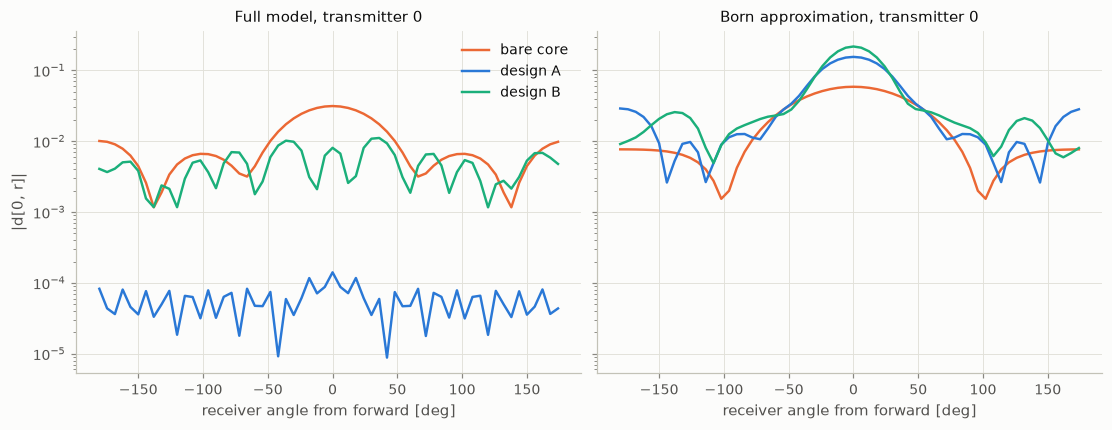

bare core  forward receiver: Born |d| / Born |d_bare| =   1.00, full |d| / full |d_bare| =   1.00, phase coherence of the Born sum = 0.998
design A   forward receiver: Born |d| / Born |d_bare| =   2.64, full |d| / full |d_bare| =   0.00, phase coherence of the Born sum = 0.969


design B   forward receiver: Born |d| / Born |d_bare| =   3.70, full |d| / full |d_bare| =   0.26, phase coherence of the Born sum = 0.953
Born kernel phase relative to the center pixel, pixels with r < 0.4: from   -0.01 to   10.00 deg, sector width  10.01 deg
Born kernel phase relative to the center pixel, pixels with r < 0.7: from   -0.02 to   36.62 deg, sector width  36.64 deg
Born kernel phase relative to the center pixel, pixels with r < 1.0: from   -0.04 to   79.32 deg, sector width  79.36 deg
Born kernel phase relative to the center pixel, pixels with r < 1.4: from   -0.07 to  151.87 deg, sector width 151.94 deg
path excess transmitter 0 - pixel - receiver 30 over the straight line, pixels with r < 1.4: from 0.0002 to 0.4220 wavelengths (half-plane condition: below 0.5)
PASS  forward receiver: path excess over the whole design region is below half a wavelength: got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  forward receiver: Born kernels over the whole design region (r < 1.4) f

Born model, transmitter 0, all 60 receivers: best first-order residual with 0 <= chi_shell <= 3: -0.51 dB; with chi_shell unconstrained: -282.4 dB (smallest chi -1.42, largest 1.15)
bare core: ||d_full - d_Born|| / ||d_full|| = 2.40; phase advance across the core, k0 (n - 1) 2a = 3.68 rad
PASS  first-order cancellation with a nonnegative bounded shell reduces the cloaked view by less than 3 dB: got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  first-order cancellation needs negative contrast when it is deep: got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  the full model beats the best bounded first-order cancellation for the cloaked view (design A): got 1, target 1, |diff| 0.00e+00 <= 0e+00
integral of chi: core 1.0039, shell of A 1.6932, shell of B 2.8840 (wavelengths^2)


homogeneous cylinder, eps = 3, radius 0.4: integral of sigma_ext over wavelength / integral of chi = 9.8682 (pi^2 = 9.8696)
PASS  sum rule for eps = 3, radius 0.4: ratio against pi^2: got 9.8682, target 9.8696, |diff| 1.40e-03 <= 2e-02


homogeneous cylinder, eps = 2, radius 1.0: integral of sigma_ext over wavelength / integral of chi = 9.8674 (pi^2 = 9.8696)
PASS  sum rule for eps = 2, radius 1.0: ratio against pi^2: got 9.86741, target 9.8696, |diff| 2.20e-03 <= 2e-02
sum rule, integrated extinction relative to the bare core, equal to the ratio of the integrals of chi: core 1.00, design A 2.69, design B 3.87
PASS  design A carries more integrated extinction than the bare core by the sum rule: got 1, target 1, |diff| 0.00e+00 <= 0e+00


In [9]:
# Section 3: Born amplitude and full data at transmitter 0, as a function of the receiver angle from forward.
fwd_dir = 30                                  # receiver 30 sits at angle 180 deg, straight behind the object
ang_from_fwd = ((ang_rx - 180.0 + 180.0) % 360.0) - 180.0
order = np.argsort(ang_from_fwd)
born = lambda chi: np.asarray(fwd.born(jnp.asarray(chi)))
cases = {"bare core": (chi_core, CAT[1]), "design A": (chiA, CAT[0]), "design B": (chiB, CAT[2])}
fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.8), sharey=True)
for name, (chi, col) in cases.items():
    axs[0].semilogy(ang_from_fwd[order], np.abs(np.asarray(fwd(jnp.asarray(chi))[0])[0])[order], color=col, label=name)
    axs[1].semilogy(ang_from_fwd[order], np.abs(born(chi)[0])[order], color=col, label=name)
axs[0].set_title("Full model, transmitter 0"); axs[1].set_title("Born approximation, transmitter 0")
for ax in axs: ax.set_xlabel("receiver angle from forward [deg]")
axs[0].set_ylabel("|d[0, r]|"); axs[0].legend()
plt.show()
W0 = np.asarray(fwd.R.reshape(60, 64, 64)) * np.asarray(fwd.u_inc[0])[None]      # Born kernel of transmitter 0 to every receiver, (60, 64, 64)
w_fwd = W0[fwd_dir]
for name, (chi, _) in cases.items():
    kern = chi * w_fwd
    coh = abs(kern.sum()) / np.abs(kern).sum()
    ratio = abs(born(chi)[0, fwd_dir]) / abs(born(chi_core)[0, fwd_dir])
    full = abs(np.asarray(fwd(jnp.asarray(chi))[0])[0, fwd_dir]) / abs(d0[0, fwd_dir])
    print(f"{name:10s} forward receiver: Born |d| / Born |d_bare| = {ratio:6.2f}, full |d| / full |d_bare| = {full:6.2f}, phase coherence of the Born sum = {coh:.3f}")
# Half-plane test, forward receiver: signed phase of the Born kernel relative to the pixel nearest the center, and the path excess.
phase = np.degrees(np.angle(w_fwd / w_fwd[32, 32]))
for rmax in (0.4, 0.7, 1.0, 1.4):
    sel = RR < rmax
    print(f"Born kernel phase relative to the center pixel, pixels with r < {rmax}: from {phase[sel].min():7.2f} to {phase[sel].max():7.2f} deg, sector width {phase[sel].max() - phase[sel].min():6.2f} deg")
tx0, rxf = setup.antennas.tx[0], setup.antennas.rx[fwd_dir]
excess = np.hypot(X - tx0[0], Y - tx0[1]) + np.hypot(X - rxf[0], Y - rxf[1]) - np.linalg.norm(tx0 - rxf)
print(f"path excess transmitter 0 - pixel - receiver {fwd_dir} over the straight line, pixels with r < 1.4: from {excess[RR < 1.4].min():.4f} to {excess[RR < 1.4].max():.4f} wavelengths (half-plane condition: below 0.5)")
check("forward receiver: path excess over the whole design region is below half a wavelength", float(excess[RR < 1.4].max() < 0.5), 0.0, 1.0)
check("forward receiver: Born kernels over the whole design region (r < 1.4) fit in a sector narrower than 180 degrees",
      float(np.abs(phase[RR < 1.4]).max() < 180.0 and phase[RR < 1.4].max() - phase[RR < 1.4].min() < 180.0), 0.0, 1.0)
check("Born forward amplitude of design A exceeds that of the bare core", float(abs(born(chiA)[0, fwd_dir]) > abs(born(chi_core)[0, fwd_dir])), 0.0, 1.0)
check("Born forward amplitude of design B exceeds that of the bare core", float(abs(born(chiB)[0, fwd_dir]) > abs(born(chi_core)[0, fwd_dir])), 0.0, 1.0)
# For every receiver: smallest sector of the complex plane containing the kernel phases over the design region
def sector_width(wv):
    p = np.sort(np.angle(wv[RR < 1.4]))
    return np.degrees(2 * np.pi - np.diff(np.concatenate([p, [p[0] + 2 * np.pi]])).max())
widths = np.array([sector_width(W0[j]) for j in range(60)])
born_core = np.abs((W0 * chi_core[None]).sum(axis=(1, 2))) ** 2
one_sided = widths < 180.0
print(f"receivers whose Born kernels over the design region fit in one half-plane: {one_sided.sum()} of 60; their share of the bare core's Born energy: {born_core[one_sided].sum() / born_core.sum():.3f}")
core_amp = (chi_core * w_fwd).sum()
shell_phases = []
for name, chi in (("design A", chiA), ("design B", chiB)):
    for lab, m in (("inner shell, r < 1.0", RR < 1.0), ("outer shell, r > 1.0", RR >= 1.0)):
        c = ((chi - chi_core) * m * w_fwd).sum() / core_amp
        shell_phases.append(abs(np.degrees(np.angle(c))))
        print(f"{name}: {lab:21s} Born contribution relative to the core's: magnitude {abs(c):5.2f}, phase {np.degrees(np.angle(c)):7.1f} deg")
check("every shell part adds to the core's Born amplitude within 90 degrees (largest |phase| versus 0)", max(shell_phases), 90.0)
# First-order cancellation of the whole transmitter-0 row of data, 60 receivers, nonnegative bounded contrast on the shell
from scipy.optimize import lsq_linear
Ash = W0[:, shell]; bb = -(W0 * chi_core[None]).sum(axis=(1, 2))
Ar, br = np.concatenate([Ash.real, Ash.imag]), np.concatenate([bb.real, bb.imag])
sol_b = lsq_linear(Ar, br, bounds=(0.0, 3.0), tol=1e-12, max_iter=2000)
sol_u = np.linalg.lstsq(Ar, br, rcond=None)[0]
J_born_b = dB(np.sum((Ar @ sol_b.x - br) ** 2) / np.sum(br ** 2))
J_born_u = dB(max(np.sum((Ar @ sol_u - br) ** 2) / np.sum(br ** 2), 1e-30))
print(f"Born model, transmitter 0, all 60 receivers: best first-order residual with 0 <= chi_shell <= 3: {J_born_b:.2f} dB; with chi_shell unconstrained: {J_born_u:.1f} dB (smallest chi {sol_u.min():.2f}, largest {sol_u.max():.2f})")
dfull0 = d0
dborn0 = np.asarray(born(chi_core))
print(f"bare core: ||d_full - d_Born|| / ||d_full|| = {np.linalg.norm(dfull0 - dborn0) / np.linalg.norm(dfull0):.2f}; phase advance across the core, k0 (n - 1) 2a = {2 * np.pi * (np.sqrt(3.0) - 1) * 0.8:.2f} rad")
check("first-order cancellation with a nonnegative bounded shell reduces the cloaked view by less than 3 dB", float(J_born_b > -3.0), 0.0, 1.0)
check("first-order cancellation needs negative contrast when it is deep", float(J_born_u < -30.0 and sol_u.min() < 0.0), 0.0, 1.0)
check("the full model beats the best bounded first-order cancellation for the cloaked view (design A)", float(Jdb(dd["A"], d0, T0) < J_born_b - 20.0), 0.0, 1.0)
print(f"integral of chi: core {chi_core.sum() * grid.h**2:.4f}, shell of A {(chiA - chi_core).sum() * grid.h**2:.4f}, shell of B {(chiB - chi_core).sum() * grid.h**2:.4f} (wavelengths^2)")

# Sum rule  int sigma_ext d lambda = pi^2 int chi dA  (TM), checked with the Mie series of a homogeneous cylinder of index m and radius a.
from scipy.special import jv, jvp, hankel1, h1vp
def sigma_ext_over_a(x, m):
    """Extinction width of a homogeneous cylinder (TM, index m) divided by its radius, at x = k a (array)."""
    n = np.arange(0, int(x.max() + 10 * x.max() ** (1 / 3) + 12) + 1)[:, None]
    X = x[None, :]
    num = jv(n, m * X) * jvp(n, X) - m * jv(n, X) * jvp(n, m * X)
    den = jv(n, m * X) * h1vp(n, X) - m * hankel1(n, X) * jvp(n, m * X)
    return (4.0 / x) * np.real(np.sum(np.where(n == 0, 1.0, 2.0) * num / den, axis=0))
def integrated_extinction(m, a, xmax=60.0, npts=4001):
    """int sigma_ext d lambda with lambda = 2 pi a / x; the tail beyond xmax uses sigma_ext -> 4 a (extinction paradox)."""
    xs = np.linspace(1e-3, xmax, npts)
    f = np.concatenate([sigma_ext_over_a(c, m) for c in np.array_split(xs, 6)])
    return 2 * np.pi * a**2 * (np.trapezoid(f / xs**2, xs) + 4.0 / xmax)
for m_idx, a_cyl in ((np.sqrt(3.0), 0.4), (np.sqrt(2.0), 1.0)):
    ratio_sr = integrated_extinction(m_idx, a_cyl) / ((m_idx**2 - 1) * np.pi * a_cyl**2)
    print(f"homogeneous cylinder, eps = {m_idx**2:.0f}, radius {a_cyl}: integral of sigma_ext over wavelength / integral of chi = {ratio_sr:.4f} (pi^2 = {np.pi**2:.4f})")
    check(f"sum rule for eps = {m_idx**2:.0f}, radius {a_cyl}: ratio against pi^2", ratio_sr, 0.02, np.pi**2)
I_chi = {k: c.sum() * grid.h**2 for k, c in (("core", chi_core), ("design A", chiA), ("design B", chiB))}
print("sum rule, integrated extinction relative to the bare core, equal to the ratio of the integrals of chi: "
      + ", ".join(f"{k} {v / I_chi['core']:.2f}" for k, v in I_chi.items()))
check("design A carries more integrated extinction than the bare core by the sum rule", float(I_chi["design A"] > I_chi["core"]), 0.0, 1.0)

## 4. Frequency

The permittivity map and geometry are fixed and the wavelength is changed (no material dispersion): `Setup(grid, antennas, wavelength=...)` with a new `Forward` for each value, about 15 wavelengths between 0.8 and 1.25 plus the design wavelength and the two 5 percent detunings. Each ratio is against the bare core at the same wavelength. The bandwidth of design A is the connected interval around the design wavelength where $J_{\{0\}}$ stays below $-10$ dB; its ends are found by root finding, and the linear interpolation on the sweep grid is printed for comparison. The sweep also reports the connected interval where the reduction is merely below 0 dB. The book's single-frequency caveat (CLAIMS H1 and H4, book section 33) concerns the ideal transformation cloak, whose lining needs a vanishing principal value by eq. (33.5) and hence, outside the book, a dispersive medium; it does not carry over directly to a nondispersive dielectric with $\epsilon_r\in[1,4]$. The narrowness seen here is an interference effect of a frequency-independent shell, and the sweep measures it without testing its cause.

wavelength A: T={0}  all   B: T={0}  all  
    0.8000      1.03   3.09        2.97   2.36  
    0.8321      0.08   2.57        2.00   1.93  
    0.8643     -1.74   2.16        0.64   0.94  
    0.8964     -3.54   2.00       -1.10  -0.33  
    0.9286     -4.91   2.06       -3.06  -1.72  
    0.9500     -7.11   2.16       -4.69  -3.08  
    0.9600     -8.98   2.20       -5.63  -3.95  
    0.9607     -9.14   2.21       -5.70  -4.01  
    0.9700    -11.64   2.25       -6.66  -4.94  
    0.9800    -15.48   2.30       -7.61  -5.97  
    0.9900    -21.86   2.33       -8.14  -6.81  
    0.9929    -24.87   2.34       -8.15  -6.97  
    1.0000    -46.54   2.36       -7.87  -7.16  
    1.0100    -22.45   2.36       -6.89  -6.88  
    1.0200    -16.57   2.35       -5.63  -6.13  
    1.0250    -14.65   2.33       -5.02  -5.67  
    1.0300    -13.04   2.31       -4.45  -5.20  
    1.0400    -10.45   2.26       -3.46  -4.31  
    1.0500     -8.40   2.20       -2.67  -3.52  
    1.0571     -7.20   2.1

design A, J(T={0}) < -10 dB: root-found [0.9643, 1.0420], fractional bandwidth 7.8 percent; grid interpolation [0.9639, 1.0422], 7.8 percent
design A, T={0}: J < 0 dB for wavelength in [0.834, 1.244] (ends of the swept range are 0.80 and 1.25)
design B, all tx: J < 0 dB for wavelength in [0.888, 1.209] (ends of the swept range are 0.80 and 1.25)
design A, all tx: J ranges over [1.92, 3.09] dB across the sweep
PASS  design A scatters more than the bare core, summed over all transmitters, at every swept wavelength: got 1, target 1, |diff| 0.00e+00 <= 0e+00
design A, T={0} : largest off-design ratio   1.03 dB at wavelength 0.8000
design A, all tx: largest off-design ratio   3.09 dB at wavelength 0.8000
design B, T={0} : largest off-design ratio   2.97 dB at wavelength 0.8000
design B, all tx: largest off-design ratio   2.36 dB at wavelength 0.8000
design C, T={0} : largest off-design ratio   1.37 dB at wavelength 0.8000
design C, all tx: largest off-design ratio   1.75 dB at wavelength 0.

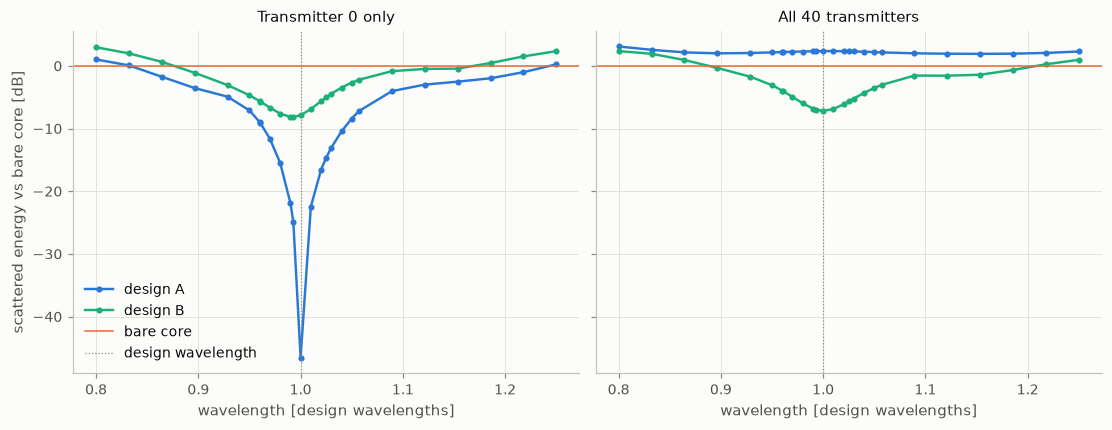

In [10]:
# Section 4: wavelength sweep. Geometry and permittivity fixed (no dispersion); a new Forward per wavelength.
waves = np.unique(np.round(np.concatenate([np.linspace(0.8, 1.25, 15), [0.95, 1.0, 1.05], np.linspace(0.96, 1.04, 9)]), 6))   # denser near the notch
chis = {"bare": chi_core, **designs}
sweep = {}
for w in waves:
    fw = Forward(Setup(grid, setup.antennas, wavelength=float(w)), tol=1e-6, restart=60)
    sweep[round(float(w), 6)] = {k: np.asarray(fw(jnp.asarray(c))[0]) for k, c in chis.items()}
Jw = {k: {"T0": np.array([Jdb(sweep[round(float(w), 6)][k], sweep[round(float(w), 6)]["bare"], T0) for w in waves]),
          "all": np.array([Jdb(sweep[round(float(w), 6)][k], sweep[round(float(w), 6)]["bare"], ALL) for w in waves])} for k in "ABC"}
i1 = int(np.argmin(np.abs(waves - 1.0)))
print(f"{'wavelength':>10s} " + " ".join(f"{k}: T={{0}}  all  " for k in "AB"))
for i, w in enumerate(waves):
    print(f"{w:10.4f} " + " ".join(f"{Jw[k]['T0'][i]:9.2f} {Jw[k]['all'][i]:6.2f}  " for k in "AB"))
check("wavelength 1.0 of the sweep reproduces the design table (A, T={0}, dB)", Jw["A"]["T0"][i1], 1e-6, Jdb(dd["A"], d0, T0))

def band(y, level):
    """Contiguous interval around the design wavelength where y < level: interpolated ends and the bracketing grid indices."""
    lo = i1
    while lo > 0 and y[lo - 1] < level: lo -= 1
    hi = i1
    while hi < len(y) - 1 and y[hi + 1] < level: hi += 1
    cross = lambda a, b: waves[a] + (level - y[a]) * (waves[b] - waves[a]) / (y[b] - y[a])
    left = waves[0] if lo == 0 else cross(lo - 1, lo)
    right = waves[-1] if hi == len(y) - 1 else cross(hi, hi + 1)
    return left, right, lo, hi
def JA_T0(w):   # exact J of design A for transmitter 0 at wavelength w, in dB, minus the -10 dB level
    fw = Forward(Setup(grid, setup.antennas, wavelength=float(w)), tol=1e-6, restart=60)
    return Jdb(np.asarray(fw(jnp.asarray(chiA))[0]), np.asarray(fw(jnp.asarray(chi_core))[0]), T0) + 10.0
from scipy.optimize import brentq
lo_i, hi_i, lo, hi = band(Jw["A"]["T0"], -10.0)
lo_r = brentq(JA_T0, waves[lo - 1], waves[lo], xtol=1e-5)
hi_r = brentq(JA_T0, waves[hi], waves[hi + 1], xtol=1e-5)
print(f"design A, J(T={{0}}) < -10 dB: root-found [{lo_r:.4f}, {hi_r:.4f}], fractional bandwidth {(hi_r - lo_r) * 100:.1f} percent;"
      f" grid interpolation [{lo_i:.4f}, {hi_i:.4f}], {(hi_i - lo_i) * 100:.1f} percent")
for k, key, lab in (("A", "T0", "A, T={0}"), ("B", "all", "B, all tx")):
    l0, h0, _, _ = band(Jw[k][key], 0.0)
    print(f"design {lab}: J < 0 dB for wavelength in [{l0:.3f}, {h0:.3f}] (ends of the swept range are {waves[0]:.2f} and {waves[-1]:.2f})")
print(f"design A, all tx: J ranges over [{Jw['A']['all'].min():.2f}, {Jw['A']['all'].max():.2f}] dB across the sweep")
check("design A scatters more than the bare core, summed over all transmitters, at every swept wavelength", float(Jw["A"]["all"].min() > 0), 0.0, 1.0)
off = waves != 1.0
for k in "ABC":
    for key, lab in (("T0", "T={0}"), ("all", "all tx")):
        y = Jw[k][key]; j = np.argmax(np.where(off, y, -np.inf))
        print(f"design {k}, {lab:6s}: largest off-design ratio {y[j]:6.2f} dB at wavelength {waves[j]:.4f}")
check("design A is deeper than -10 dB at its design wavelength", float(Jw["A"]["T0"][i1] < -10), 0.0, 1.0)

fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.8), sharey=True)
for ax, key, t in zip(axs, ("T0", "all"), ("Transmitter 0 only", "All 40 transmitters")):
    for k, col in (("A", CAT[0]), ("B", CAT[2])):
        ax.plot(waves, Jw[k][key], color=col, marker="o", ms=3, label=f"design {k}")
    ax.axhline(0, color=CAT[1], lw=1.0, label="bare core")
    ax.axvline(1.0, color=MUTED, lw=0.8, ls=":", label="design wavelength")
    ax.set_xlabel("wavelength [design wavelengths]"); ax.set_title(t)
axs[0].set_ylabel("scattered energy vs bare core [dB]"); axs[0].legend()
plt.show()

## 5. Detectability with the testbed's noise

Noise is circular complex Gaussian, $y = d + e$ with $e\sim\mathcal{CN}(0,s^2)$ per entry, and the misfit is $\Phi = \sum|d - d_{\mathrm{obs}}|^2/s^2$ (`bayes_scatter.likelihood`). Fix $s$ once from the bare core's full data at 30 dB. "Is anything there?" against the empty domain is a known-signal test, $H_0: y = e$ against $H_1: y = d + e$. The log-likelihood ratio is
$$\Lambda = \ln\frac{p(y\mid H_1)}{p(y\mid H_0)} = \frac{\|y\|^2 - \|y - d\|^2}{s^2} = \frac{2\,\mathrm{Re}\langle d, y\rangle - \|d\|^2}{s^2}.$$
$\mathrm{Re}\langle d,e\rangle = \sum(\mathrm{Re}\,d\,\mathrm{Re}\,e + \mathrm{Im}\,d\,\mathrm{Im}\,e)$ has variance $\|d\|^2 s^2/2$, so under both hypotheses $\Lambda$ is Gaussian with variance $2E$, where
$$E = \frac{\|d\|^2}{s^2}$$
is the signal energy in noise units; its mean is $-E$ under $H_0$ and $+E$ under $H_1$. The detection index (separation of the means over the common standard deviation) is $d' = 2E/\sqrt{2E} = \sqrt{2E}$, and the likelihood-ratio test at threshold zero errs with probability $Q(d'/2) = Q(\sqrt{E/2})$ under either hypothesis. $E/N$ in dB is the signal-to-noise ratio per datum in the project's convention. For bare core data over all views it is 30 dB by construction.

The table gives $E$ and $E/N$ in dB for the bare core and the three designs, with transmitter 0 only and with all transmitters, at the design wavelength and 5 percent either side. These data come from the same operator that the designs were tuned on (the $64\times64$ grid), an inverse-crime setting. A second table gives $E$ and $d'$ for transmitter 0 for the three versions of design A of section 2 when the data come from the $64$, $128$ or $256$ grid: a design is hidden only if the operator that measures it agrees with the one that built it to better than the noise. A Monte Carlo run with a fixed seed verifies the formulas for design A with data from its own operator (the histogram is standardized by $\sqrt{2E}$), and one noisy draw each for design A and the empty domain shows the misfit against zero data, with expectation $N + E$ and variance $N + 2E$ for $N$ complex entries.

In [11]:
# Section 5: energy in noise units. s is fixed once, from the bare core's full data set at 30 dB.
s = noise_std_from_snr(d0, 30.0)
cases5 = {"bare core": "bare", "design A": "A", "design B": "B", "design C": "C"}
wl = [1.0, 1.05, 0.95]
def E(d, tsel): return float(np.sum(np.abs(d[tsel]) ** 2) / s**2)
print(f"noise level s = {s:.4e}")
print(f"{'':10s} " + " ".join(f"| lambda={w:4.2f}: {lab:>16s}" for w in wl for lab in ("T={0}: E, dB/dat", "all: E, dB/dat")))
for name, key in cases5.items():
    row = []
    for w in wl:
        d = sweep[round(w, 6)][key]
        for tsel in (T0, ALL):
            e = E(d, tsel); row.append(f"{e:10.3g} {dB(e / (len(tsel) * 60)):6.1f}")
    print(f"{name:10s} " + " | ".join(row))
print("detection index d' = sqrt(2 E), design wavelength:")
for name, key in cases5.items():
    print(f"  {name:10s} T={{0}}: {np.sqrt(2 * E(sweep[1.0][key], T0)):8.2f}   all: {np.sqrt(2 * E(sweep[1.0][key], ALL)):8.2f}")
print("single-view designs, transmitter 0, design wavelength: E and d' = sqrt(2E) when the data come from the grid in the column (n = 64 is the design grid of A):")
print(f"{'version':26s} " + " ".join(f"| n={64 * f:3d}: {'E':>9s} {'d_prime':>8s}" for f in (1, 2, 4)))
for name in vname:
    es = [float(np.sum(np.abs(rows0[(name, f)]) ** 2) / s**2) for f in (1, 2, 4)]
    print(f"{name:26s} " + " ".join(f"|       {e:9.3g} {np.sqrt(2 * e):8.2f}" for e in es))
dprime0 = {key: np.sqrt(2 * float(np.sum(np.abs(rows0[key]) ** 2) / s**2)) for key in rows0}
check("design A is hidden (d' < 3) when data and design share the n = 64 operator", float(dprime0[(vname[0], 1)] < 3.0), 0.0, 1.0)
check("design A is detectable (d' > 5) when the data come from the n = 128 grid", float(dprime0[(vname[0], 2)] > 5.0), 0.0, 1.0)
check("design A is detectable (d' > 5) when the data come from the n = 256 grid", float(dprime0[(vname[0], 4)] > 5.0), 0.0, 1.0)
check("the version re-tuned on n = 128 is hidden (d' < 3) on n = 128 and detectable (d' > 5) on n = 64", float(dprime0[(vname[2], 2)] < 3.0 and dprime0[(vname[2], 1)] > 5.0), 0.0, 1.0)

noise level s = 4.2457e-04
           | lambda=1.00: T={0}: E, dB/dat | lambda=1.00:   all: E, dB/dat | lambda=1.05: T={0}: E, dB/dat | lambda=1.05:   all: E, dB/dat | lambda=0.95: T={0}: E, dB/dat | lambda=0.95:   all: E, dB/dat
bare core       6e+04   30.0 |    2.4e+06   30.0 |   6.55e+04   30.4 |   2.62e+06   30.4 |   5.96e+04   30.0 |   2.39e+06   30.0
design A         1.33  -16.5 |   4.13e+06   32.4 |   9.48e+03   22.0 |   4.34e+06   32.6 |   1.16e+04   22.9 |   3.92e+06   32.1
design B      9.8e+03   22.1 |   4.61e+05   22.8 |   3.55e+04   27.7 |   1.16e+06   26.9 |   2.03e+04   25.3 |   1.18e+06   26.9
design C     1.72e+04   24.6 |   7.56e+05   25.0 |   4.21e+04   28.5 |    1.4e+06   27.7 |   2.73e+04   26.6 |   1.19e+06   26.9
detection index d' = sqrt(2 E), design wavelength:
  bare core  T={0}:   346.49   all:  2190.89
  design A   T={0}:     1.63   all:  2874.64
  design B   T={0}:   139.99   all:   960.31
  design C   T={0}:   185.53   all:  1229.87
single-view designs, tr

design A   transmitter 0: E = 1.333; mean LLR under empty -1.353 (theory -1.333), under signal 1.349 (theory 1.333); std 1.634 / 1.641 (theory 1.633); d' = 1.65 vs sqrt(2E) = 1.633
PASS  design A: empirical d' / sqrt(2E): got 1.01084, target 1, |diff| 1.08e-02 <= 2e-02
bare core  transmitter 0: E = 6.003e+04; mean LLR under empty -6.003e+04 (theory -6.003e+04), under signal 6.003e+04 (theory 6.003e+04); std 346 / 346.2 (theory 346.5); d' = 346.9 vs sqrt(2E) = 346.5
PASS  bare core: empirical d' / sqrt(2E): got 1.00116, target 1, |diff| 1.16e-03 <= 2e-02


empty domain: Phi(zero data) =  55.31; expected  60.00 +- 7.75; LLR of the signal-hypothesis against empty =  -2.62
PASS  empty domain: Phi(zero data) within 3 sigma of its expectation (sanity of this one seeded draw): got 55.3124, target 60, |diff| 4.69e+00 <= 2e+01
design A    : Phi(zero data) =  63.38; expected  61.33 +- 7.92; LLR of the signal-hypothesis against empty =   1.55
PASS  design A: Phi(zero data) within 3 sigma of its expectation (sanity of this one seeded draw): got 63.3783, target 61.3326, |diff| 2.05e+00 <= 2e+01


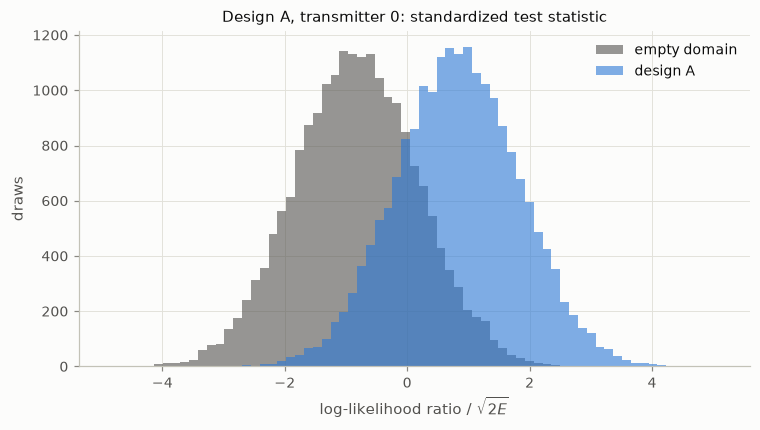

In [12]:
# Stochastic illustration (fixed seed): Monte Carlo of the log-likelihood-ratio statistic of the known-signal test.
from bayes_scatter.likelihood import misfit
N_MC = 20000
k1, k2, k3, k4 = jax.random.split(jax.random.PRNGKey(7), 4)
def llr(dsig, y):
    """log p(y | signal) - log p(y | empty) = (2 Re <d, y> - |d|^2) / s^2, summed over the data used."""
    return np.asarray((2.0 * jnp.real(jnp.sum(jnp.conj(dsig) * y, axis=-1)) - jnp.sum(jnp.abs(dsig) ** 2)) / s**2)
stat = {}
for name, key in (("design A", "A"), ("bare core", "bare")):
    ds = jnp.asarray(sweep[1.0][key][0])
    L1 = llr(ds, add_noise(k1, jnp.broadcast_to(ds, (N_MC, 60)), s))
    L0 = llr(ds, add_noise(k2, jnp.zeros((N_MC, 60)), s))
    e = E(sweep[1.0][key], T0)
    dp = (L1.mean() - L0.mean()) / np.sqrt(0.5 * (L1.var() + L0.var()))
    stat[name] = (L0, L1, e)
    print(f"{name:10s} transmitter 0: E = {e:.4g}; mean LLR under empty {L0.mean():.4g} (theory {-e:.4g}), under signal {L1.mean():.4g} (theory {e:.4g}); "
          f"std {np.sqrt(L0.var()):.4g} / {np.sqrt(L1.var()):.4g} (theory {np.sqrt(2 * e):.4g}); d' = {dp:.4g} vs sqrt(2E) = {np.sqrt(2 * e):.4g}")
    check(f"{name}: empirical d' / sqrt(2E)", dp / np.sqrt(2 * e), 0.02, 1.0)   # sampling error of d' is about 1 percent for 20000 draws

# one noisy data set each, misfit to zero data (Phi(0) = sum |d_obs|^2 / s^2, expectation N + E, variance N + 2E)
dA0 = jnp.asarray(sweep[1.0]["A"][0])
y_A, y_empty = add_noise(k3, dA0, s), add_noise(k4, jnp.zeros(60), s)
Nd = 60
for name, y, e in (("empty domain", y_empty, 0.0), ("design A", y_A, E(sweep[1.0]["A"], T0))):
    phi0 = float(misfit(jnp.zeros(60), y, s))
    print(f"{name:12s}: Phi(zero data) = {phi0:6.2f}; expected {Nd + e:6.2f} +- {np.sqrt(Nd + 2 * e):.2f}; "
          f"LLR of the signal-hypothesis against empty = {llr(dA0, y):6.2f}")
    check(f"{name}: Phi(zero data) within 3 sigma of its expectation (sanity of this one seeded draw)", phi0, 3 * np.sqrt(Nd + 2 * e), Nd + e)

L0, L1, e = stat["design A"]
fig, ax = plt.subplots(figsize=(6.8, 3.8))
bins = np.linspace(min(L0.min(), L1.min()), max(L0.max(), L1.max()), 70) / np.sqrt(2 * e)
ax.hist(L0 / np.sqrt(2 * e), bins=bins, color=INK2, alpha=0.6, label="empty domain")
ax.hist(L1 / np.sqrt(2 * e), bins=bins, color=CAT[0], alpha=0.6, label="design A")
ax.set_title("Design A, transmitter 0: standardized test statistic"); ax.set_xlabel("log-likelihood ratio / $\\sqrt{2E}$"); ax.set_ylabel("draws"); ax.legend()
plt.show()

## 6. Does the cloak reduce the local sensitivity of the data?

Signal and sensitivity are different objects. Let $J = \partial d/\partial\theta$ with $\theta = \log\epsilon_r$ (`jacobian_theta`, a dense $2400\times 4096$ complex matrix, rows ordered transmitter by transmitter). With real $\theta$ and circular noise of variance $s^2/2$ per real component, the Fisher information is $F = (2/s^2)\,\mathrm{Re}(J^HJ)$ (`gauss_newton_hessian_dense`). For a unit-norm $\delta\theta$ along an eigenvector with eigenvalue $\lambda$ the shifted data have $E = \lambda/2$ in the notation of section 5, so $d' = \sqrt{\lambda}$, and the number of eigenvalues above 1 counts the pixel-basis directions detectable at $d'>1$; this depends on the grid, so counts compare configurations on this grid only. The cell evaluates the spectrum at the empty domain, the bare core, designs A and B and a control that is not a cloak (a solid $\epsilon_r = 4$ disk on $r<1.4$), for all views and for transmitter 0 alone (at most 120 directions). The question is local: does the cloak reduce the sensitivity of the data to permittivity changes? A direct measure is the detection index of a 1 percent change of the core permittivity, with and without cloak. The dense Jacobian is first checked against a finite difference. Whether the cloak can be imaged from the cloaked view is the question of section 5.

PASS  Jacobian vs finite difference (design B), relative error: got 6.8038e-08, target 0, |diff| 6.80e-08 <= 1e-05
PASS  Jacobian rows 0..59 are transmitter 0 (design B), relative error: got 2.07332e-08, target 0, |diff| 2.07e-08 <= 1e-05


all 40 transmitters (4096 parameters):
configuration               largest  #>1e4  #>100    #>1  #>1e-2      trace
empty domain               2.32e+05    224    300    361     422   6.21e+06
bare core                  3.47e+05    221    310    379     443   7.37e+06
design A                   5.37e+05    233    328    396     467      1e+07
design B                   1.24e+06    230    332    408     483   1.49e+07
eps = 4 disk (control)     1.29e+06    274    447    541     613   1.99e+07
transmitter 0 only (at most 120 directions):
configuration               largest  #>100    #>1      trace
empty domain               6.27e+03     62     76   1.54e+05
bare core                   1.7e+04     63     77   1.85e+05
design A                   2.56e+04     63     77   2.52e+05
design B                   5.47e+04     63     77    3.9e+05
eps = 4 disk (control)     6.21e+04     61     73   4.59e+05
detection index of a 1 percent change of the core permittivity (core pixels only), through tra

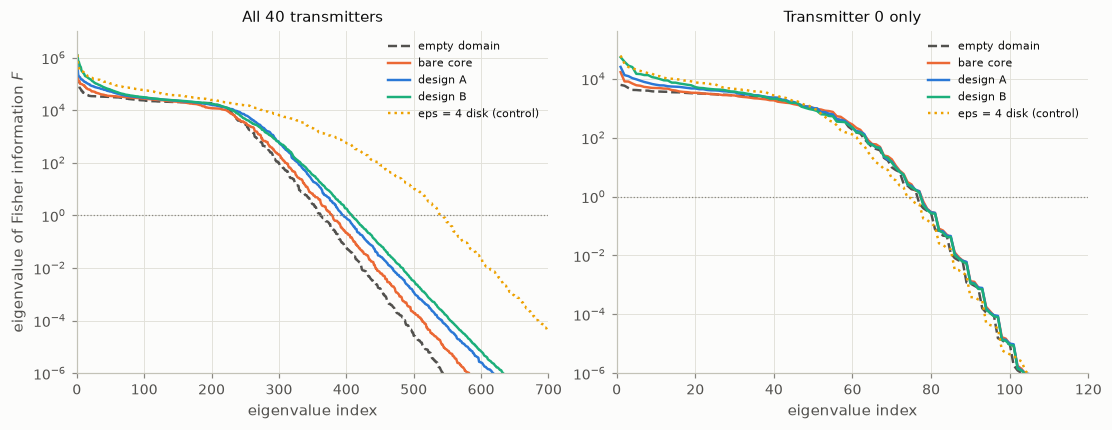

In [13]:
# Section 6: Fisher information F = (2/s^2) Re(J^H J) of the data with respect to theta = log eps_r.
from bayes_scatter.jacobian import gauss_newton_hessian_dense
core_dth = 0.01 * (chi_core > 0).ravel()          # a 1 percent change of the core permittivity, in theta = log eps_r
def fisher_spectra(chi):
    Jm = np.asarray(jacobian_theta(fwd, jnp.log1p(jnp.asarray(chi))))
    F = np.asarray(gauss_newton_hessian_dense(Jm, s))
    full = np.linalg.eigvalsh(F)[::-1]
    M = np.sqrt(2.0) / s * np.concatenate([Jm[:60].real, Jm[:60].imag], axis=0)     # transmitter 0: F_0 = M^T M, same nonzero eigenvalues as M M^T
    return full, np.linalg.eigvalsh(M @ M.T)[::-1], float(np.sqrt(core_dth @ F @ core_dth)), float(np.linalg.norm(M @ core_dth))
# self-check of the dense Jacobian on design B: J v against a central difference of the forward model
Jm_B = np.asarray(jacobian_theta(fwd10, jnp.log1p(jnp.asarray(chiB))))
vth = np.zeros((64, 64)); vth[shell] = rng.standard_normal(shell.sum()); vth /= np.linalg.norm(vth)
th_B = np.log1p(chiB); eps_fd = 1e-3
dplus = np.asarray(fwd10(jnp.asarray(np.expm1(th_B + eps_fd * vth)))[0]); dminus = np.asarray(fwd10(jnp.asarray(np.expm1(th_B - eps_fd * vth)))[0])
fd_vec = ((dplus - dminus) / (2 * eps_fd)).ravel(); jv = Jm_B @ vth.ravel()
# tolerance: central-difference truncation ~ eps^2 times a third derivative, plus solver error 1e-10 / eps
check("Jacobian vs finite difference (design B), relative error", np.linalg.norm(jv - fd_vec) / np.linalg.norm(fd_vec), 1e-5)
check("Jacobian rows 0..59 are transmitter 0 (design B), relative error", np.linalg.norm(jv[:60] - fd_vec[:60]) / np.linalg.norm(fd_vec[:60]), 1e-5)
del Jm_B
spec, spec0, dpc = {}, {}, {}
configs6 = (("empty domain", np.zeros((64, 64))), ("bare core", chi_core), ("design A", chiA), ("design B", chiB),
            ("eps = 4 disk (control)", np.where(RR < 1.4, 3.0, 0.0)))
for name, chi in configs6:
    spec[name], spec0[name], d_all, d_tx0 = fisher_spectra(chi)
    dpc[name] = (d_tx0, d_all)
print("all 40 transmitters (4096 parameters):")
print(f"{'configuration':24s} {'largest':>10s} {'#>1e4':>6s} {'#>100':>6s} {'#>1':>6s} {'#>1e-2':>7s} {'trace':>10s}")
for name, ev in spec.items():
    print(f"{name:24s} {ev[0]:10.3g} {(ev > 1e4).sum():6d} {(ev > 100).sum():6d} {(ev > 1).sum():6d} {(ev > 1e-2).sum():7d} {ev.sum():10.3g}")
print("transmitter 0 only (at most 120 directions):")
print(f"{'configuration':24s} {'largest':>10s} {'#>100':>6s} {'#>1':>6s} {'trace':>10s}")
for name, ev in spec0.items():
    print(f"{name:24s} {ev[0]:10.3g} {(ev > 100).sum():6d} {(ev > 1).sum():6d} {ev.sum():10.3g}")
print("detection index of a 1 percent change of the core permittivity (core pixels only), through transmitter 0 and through all views:")
for name, (d_tx0, d_all) in dpc.items():
    print(f"  {name:24s} transmitter 0: {d_tx0:7.2f}   all views: {d_all:7.2f}")
print(f"one view: at most {2 * 60} real rows for {64 * 64} parameters, so the null space of the one-view Jacobian has dimension at least {64 * 64 - 2 * 60} at every configuration, cloak or not")
n1 = {name: (ev > 1).sum() for name, ev in spec.items()}
for name in ("bare core", "design A", "design B"):   # the cloak does not remove sensitive directions: the count is not below the empty domain's
    check(f"count of eigenvalues above 1, {name} against the empty domain (all views), not lower by more than 5 percent", float(n1[name] >= 0.95 * n1["empty domain"]), 0.0, 1.0)
check("the controls show the count is not a property of cloaking: it spans more than 30 percent across the objects", float(max(n1.values()) / min(n1.values()) > 1.3), 0.0, 1.0)
for name in ("design A", "design B"):
    check(f"core perturbation through transmitter 0, {name} against bare core: detection index not lower by more than 10 percent", float(dpc[name][0] >= 0.9 * dpc["bare core"][0]), 0.0, 1.0)

fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.8))
styles = {"empty domain": (INK2, "--"), "bare core": (CAT[1], "-"), "design A": (CAT[0], "-"), "design B": (CAT[2], "-"),
          "eps = 4 disk (control)": (CAT[3], ":")}
for ax, sp, t, xmax in ((axs[0], spec, "All 40 transmitters", 700), (axs[1], spec0, "Transmitter 0 only", 120)):
    for name, ev in sp.items():
        ax.semilogy(np.arange(1, len(ev) + 1), np.maximum(ev, 1e-12), color=styles[name][0], ls=styles[name][1], label=name)
    ax.axhline(1.0, color=MUTED, lw=0.8, ls=":"); ax.set_ylim(1e-6, None); ax.set_xlim(0, xmax)
    ax.set_xlabel("eigenvalue index"); ax.set_title(t); ax.legend(fontsize=7)
axs[0].set_ylabel("eigenvalue of Fisher information $F$")
plt.show()

## Summary

One transmitter can be made to see almost nothing; the notch is a single-view, single-frequency interference effect, narrow in wavelength and absent for other transmitters (design A scatters more than the bare core when all views are counted, at every swept wavelength). The design is tuned to its discretized operator more finely than that operator is accurate: on a finer grid it keeps only the depth of the model mismatch, while the same pixels re-tuned there are deep again, so a single-view null exists on every grid tried. Optimizing over all 40 transmitters gives only a modest reduction, and free pixels against rings is not ranked. At first order added dielectric cannot cancel the forward amplitude, yet the full model reaches a deep null, so the Born picture explains neither the single-view success nor the all-view limit; the rigorous statement is the sum rule.

In noise units, design A is hidden from its own transmitter only when the data come from the operator it was tuned on; with data from finer grids it is detectable, and the version re-tuned there is hidden there and detectable on the other. Every design is clearly detectable from all 40 transmitters. The Fisher spectra keep their rank around a cloak, and a 1 percent change of the hidden core is at least as detectable through the cloaked view with the cloak as without it, so the cloak does not reduce the local sensitivity of the data. This does not say the cloak can be imaged: in the shared-operator setting of section 5 the cloaked view is hard to tell from empty space (a detection index of order one, printed in section 5).

A designed cloak is a point on the zero set of the data of a restricted experiment. For one view at one frequency that set is large (far fewer real equations than design pixels; both counts are printed in section 2), so non-identifiability is exact in the model and noise plays no role. For all views, uniqueness theorems exclude an exact omnidirectional cloak (conditions in section 3), and every design here stays detectable from all 40 views.

## Caveats and open ends

- No depth of design A is precise: it depends on the optimizer path, the operator and the thread environment, and a depth below the model mismatch between discretizations is not a property of the physical object. The re-tuning uses one start, one fine grid and a limited budget.
- One object, one shell geometry, one noise level (30 dB); all designs are local optima from one or two starts.
- The half-plane argument holds for the forward receiver only, the sum rule was checked only for cylinders, and the uniqueness result is quoted, not re-derived.
- The gradient check does not test accuracy against a dense reference. The bandwidth is for a lossless, nondispersive permittivity, the Fisher information is a local linearization at fixed grid, no reconstruction was run, and the detection analysis assumes a known signal.

## References

- Leonhardt and Philbin, *Geometry and Light* (Dover 2010): section 33 with eq. (33.5); CLAIMS.md entries H1 and H4.
- DESIGN.md of this project: sections 1, 2, 4 and 8.
- R. H. Byrd, P. Lu, J. Nocedal and C. Zhu, SIAM Journal on Scientific Computing 16 (1995), "A limited memory algorithm for bound constrained optimization".
- E. Andkjaer and O. Sigmund, "Topology optimized low-contrast all-dielectric optical cloak", Applied Physics Letters 98, 021112 (2011).
- F. Monticone and A. Alu, "Do cloaked objects really scatter less?", Physical Review X 3, 041005 (2013).
- A. L. Bukhgeim, "Recovering a potential from Cauchy data in the two-dimensional case", Journal of Inverse and Ill-Posed Problems 16, 19 (2008).